In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

In [43]:
iris = datasets.load_iris()
X = iris.data
y = iris.target

In [44]:
df = pd.DataFrame(X, columns=iris.feature_names)
df['especie'] = y
print(df.head())

   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  especie
0                5.1               3.5  ...               0.2        0
1                4.9               3.0  ...               0.2        0
2                4.7               3.2  ...               0.2        0
3                4.6               3.1  ...               0.2        0
4                5.0               3.6  ...               0.2        0

[5 rows x 5 columns]


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [46]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [47]:
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale']}
]
grid = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_s, y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid=[{'C': [0.1, 1, 10], 'kernel': ['linear']},
                         {'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale'],
                          'kernel': ['rbf']}],
             scoring='accuracy')

In [ ]:
res = pd.DataFrame(grid.cv_results_)
melhores = res.loc[res.groupby('param_kernel')['mean_test_score'].idxmax(),
                    ['param_kernel', 'params', 'mean_test_score']]
print(melhores.to_string(index=False))
print('Melhor geral:', grid.best_params_, round(grid.best_score_, 4))

param_kernel                                  params  mean_test_score
      linear          {'C': 0.1, 'kernel': 'linear'}         0.975000
         rbf {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}         0.983333
Melhor geral: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'} 0.9833


In [49]:
best = grid.best_estimator_
y_pred = best.predict(X_test_s)
print('Acurácia no teste:', accuracy_score(y_test, y_pred))

Acurácia no teste: 0.9666666666666667


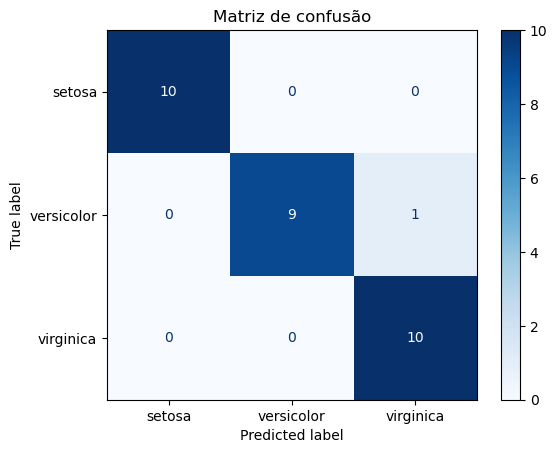

In [50]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names).plot(cmap='Blues')
plt.title('Matriz de confusão')
plt.show()